<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Haybarn](https://query.farm/products/haybarn/) · [Setup guide](README.md)

# 01 · When is the reservoir fullest?

An inflow pulse peaks halfway through a short filling cycle. Does the stored volume peak at the same time? We will derive the storage curve, prove its relationship to the flows, and locate its maximum with **SymPy through SQL**. Then we will increase the drain rate and predict what changes.

**Synthetic model, no measured data.** This is a deliberately small calculus example, not a calibrated reservoir design. Haybarn calls the real local VGI worker for differentiation, integration, solving, symbolic equality and numerical evaluation. Python draws the returned results and writes the numerical interpretation.

## Choose the pulse and the drain

Let elapsed time $t$ be measured in minutes, on the **closed interval** $0\le t\le\tau$. Inflow is $q(t)=a\,t(\tau-t)$ in litres/minute; $a$ has units L/min³. A constant drain $d$ in L/min removes water throughout the interval. Initial volume is $v_0$ litres, so conservation requires $V'(t)=q(t)-d$ and $V(0)=v_0$.

The model assumes perfect accounting: no leakage, evaporation, spill or drain shutoff. It is valid only while storage stays positive; we check its exact candidate minima before plotting. There is no calendar time or live/replay mode.

Edit parameters, then **Restart Kernel → Run All**. Accepted ranges are shown below. The drain must stay below maximum inflow, $a\tau^2/4$, so two flow crossings exist. `GRID_POINTS` controls drawing resolution; the extrema are solved symbolically, not selected from that grid.

In [1]:
DURATION_MIN = 12.0  # τ: 1–60 min, inclusive end of the pulse
PULSE_A_L_MIN3 = 0.5  # a: 0.01–2 L/min³
DRAIN_L_MIN = 8.0  # d: 0 < d < a·τ²/4 L/min; experiment: 12.0
INITIAL_VOLUME_L = 100.0  # v0: 1–10,000 L; must prevent a dry reservoir
GRID_POINTS = 121  # 51–501 inclusive sample points for charts

In [2]:
# Imports and presentation only; symbolic calculations live in the visible SQL.
import os
import sys
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Math, display

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd()
sys.path.insert(0, str(NOTEBOOK_DIR))

from notebook_support import (  # noqa: E402
    BLUE,
    GREEN,
    ORANGE,
    finish_chart,
    prose,
    set_theme,
    validate_parameters,
)

validate_parameters(DURATION_MIN, PULSE_A_L_MIN3, DRAIN_L_MIN, INITIAL_VOLUME_L, GRID_POINTS)
set_theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

# JupySQL replaces these placeholders with query result DataFrames below.
identities = expressions = turning_points = summary = curve = None

/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-sympy/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-sympy/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-sympy/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-sympy/notebooks/pyproject.toml.

In [3]:
prose(
    f"**Selected synthetic run:** 0–{DURATION_MIN:g} min (both endpoints included), "
    f"pulse coefficient **{PULSE_A_L_MIN3:g} L/min³**, drain **{DRAIN_L_MIN:g} L/min**, "
    f"initial storage **{INITIAL_VOLUME_L:g} L**. The curve uses {GRID_POINTS} time samples; "
    "all analytical values below come from the worker."
)

**Selected synthetic run:** 0–12 min (both endpoints included), pulse coefficient **0.5 L/min³**, drain **8 L/min**, initial storage **100 L**. The curve uses 121 time samples; all analytical values below come from the worker.

## Connect to the symbolic engine

The literal `uvx` command fetches public commit `ecee7f4a272ba1a5d3d86f7e6090a03c89d46ab8`
(the v0.4.0 release), installs the worker in uv's managed cache, and runs its console
entry point. It pins VGI Python 0.51.0 and SymPy 1.14.0 to the versions verified here.
No local worker checkout, root environment or inline-script dependency resolution
is required. The project is distributed on GitHub rather than PyPI.

The notebook kernel has its own locked Haybarn environment. Initial dependency and
extension downloads require network access; the synthetic calculation does not.
This diagnostic confirms the loaded extension and the worker's actual SymPy version.

In [4]:
%%sql
FORCE INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'sympy' (TYPE vgi, LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-sympy@ecee7f4a272ba1a5d3d86f7e6090a03c89d46ab8 --with vgi-python==0.51.0 --with sympy==1.14.0 vgi-sympy-worker');
SELECT version() AS engine_version, extension_name, extension_version, loaded,
       sympy.main.sympy_version(1) AS worker_sympy_version
FROM duckdb_extensions()
WHERE extension_name = 'vgi';

,engine_version,extension_name,extension_version,loaded,worker_sympy_version
0,v2.0.0,vgi,e75482339d,True,1.14.0


## Derive storage from the flow balance

We send the expression strings to the worker and keep the resulting expressions in ordinary in-memory tables. The worker supplies a primitive of net flow. For this polynomial its value at $t=0$ is zero, so adding $v_0$ imposes the initial condition; the next query verifies that fact explicitly. Integrals do not include an arbitrary constant automatically.

Separate inflow and drain primitives will also give a cumulative volume budget. No Python SymPy calls or hand-coded numerical curve replace these SQL results.

In [5]:
%%sql
CREATE OR REPLACE TABLE parameters AS
SELECT {{ DURATION_MIN }}::DOUBLE AS tau, {{ PULSE_A_L_MIN3 }}::DOUBLE AS a,
       {{ DRAIN_L_MIN }}::DOUBLE AS d, {{ INITIAL_VOLUME_L }}::DOUBLE AS v0;

CREATE OR REPLACE TABLE model AS
WITH source AS (
  SELECT 'a*t*(tau-t)' AS inflow, 'a*t*(tau-t)-d' AS net_flow
), primitives AS (
  SELECT *, sympy.main.integrate(inflow, 't') AS inflow_primitive,
         sympy.main.integrate('d', 't') AS drain_primitive,
         sympy.main.integrate(net_flow, 't') AS net_primitive
  FROM source
), storage AS (
  SELECT *, 'v0 + (' || net_primitive || ')' AS volume FROM primitives
)
SELECT *, sympy.main.differentiate(volume, 't') AS volume_slope,
       sympy.main.differentiate(sympy.main.differentiate(volume, 't'), 't') AS volume_curvature,
       sympy.main.expand(inflow) AS expanded_inflow,
       sympy.main.factor(sympy.main.expand(inflow)) AS factored_inflow
FROM storage;

SELECT inflow, expanded_inflow, net_primitive, volume_slope FROM model;

,inflow,expanded_inflow,net_primitive,volume_slope
0,a*t*(tau-t),-a*t**2 + a*t*tau,-a*t**3/3 + a*t**2*tau/2 - d*t,-a*t**2 + a*t*tau - d


In [6]:
%%sql identities <<
SELECT 'Expanded inflow equals original' AS check_name,
       sympy.main.symbolic_equal(inflow, expanded_inflow) AS passed FROM model
UNION ALL
SELECT 'Factored inflow equals original',
       sympy.main.symbolic_equal(inflow, factored_inflow) FROM model
UNION ALL
SELECT 'Storage derivative equals net flow',
       sympy.main.symbolic_equal(volume_slope, net_flow) FROM model
UNION ALL
SELECT 'Cumulative volume budget equals storage',
       sympy.main.symbolic_equal(volume, 'v0 + (' || inflow_primitive || ') - (' || drain_primitive || ')')
FROM model
UNION ALL
SELECT 'Primitive is zero at t = 0',
       abs(sympy.main.evaluate(net_primitive, json_object('t', 0, 'tau', tau, 'a', a, 'd', d))) < 1e-10
FROM model CROSS JOIN parameters
UNION ALL
SELECT 'Initial condition V(0) = v0',
       abs(sympy.main.evaluate(volume, json_object('t', 0, 'tau', tau, 'a', a, 'd', d, 'v0', v0)) - v0) < 1e-10
FROM model CROSS JOIN parameters;

In [7]:
display(identities)
assert identities.passed.notna().all() and identities.passed.all(), "A symbolic or initial-condition check failed."
prose(
    f"**{len(identities)} checks passed.** Equivalent strings describe the same inflow, and the "
    "derived storage satisfies both the flow balance and its initial condition. "
    "These are algebraic and numerical consistency checks; they do not validate the model against a real reservoir."
)

,check_name,passed
0,Expanded inflow equals original,True
1,Factored inflow equals original,True
2,Storage derivative equals net flow,True
3,Cumulative volume budget equals storage,True
4,Primitive is zero at t = 0,True
5,Initial condition V(0) = v0,True


**6 checks passed.** Equivalent strings describe the same inflow, and the derived storage satisfies both the flow balance and its initial condition. These are algebraic and numerical consistency checks; they do not validate the model against a real reservoir.

In [8]:
%%sql expressions <<
SELECT sympy.main.to_latex(inflow) AS inflow_latex,
       sympy.main.to_latex(volume) AS volume_latex,
       sympy.main.to_latex(volume_slope) AS slope_latex
FROM model;

In [9]:
display(Math(r"q(t) = " + expressions.iloc[0].inflow_latex))
display(Math(r"V(t) = " + expressions.iloc[0].volume_latex))
display(Math(r"V'(t) = " + expressions.iloc[0].slope_latex))
prose(
    "**Read the expressions with units:** q and V′ are L/min, V is L, and t and τ are min. "
    "The worker treats symbols algebraically; unit consistency comes from the declared parameter units."
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Read the expressions with units:** q and V′ are L/min, V is L, and t and τ are min. The worker treats symbols algebraically; unit consistency comes from the declared parameter units.

## Locate the turning points, then compare the boundaries

Stored volume turns where net flow is zero, not necessarily where inflow peaks. SQL solves $V'(t)=0$, substitutes the chosen parameters, and keeps real roots inside the pulse. The second derivative distinguishes a local minimum from a local maximum. We also include $t=0$ and $t=\tau$: a stationary point alone does not establish the **global** maximum over a finite interval.

In [10]:
%%sql
CREATE OR REPLACE TABLE stationary AS
WITH roots AS (
  SELECT unnest(sympy.main.solve(volume_slope, 't')) AS root FROM model
), evaluated AS (
  SELECT root, sympy.main.evaluate(root, json_object('tau', tau, 'a', a, 'd', d)) AS time_min
  FROM roots CROSS JOIN parameters
)
SELECT root, time_min
FROM evaluated CROSS JOIN parameters
WHERE time_min IS NOT NULL AND time_min > 0 AND time_min < tau;

CREATE OR REPLACE TABLE candidates AS
WITH times AS (
  SELECT 'initial boundary' AS origin, 0.0 AS time_min
  UNION ALL SELECT 'final boundary', tau FROM parameters
  UNION ALL SELECT 'stationary point', time_min FROM stationary
), values_at_times AS (
  SELECT origin, time_min,
    sympy.main.evaluate(volume, json_object('t', time_min, 'tau', tau, 'a', a, 'd', d, 'v0', v0)) AS volume_l,
    sympy.main.evaluate(volume_curvature, json_object('t', time_min, 'tau', tau, 'a', a)) AS curvature_l_min2
  FROM times CROSS JOIN model CROSS JOIN parameters
)
SELECT *, CASE WHEN origin <> 'stationary point' THEN origin
               WHEN curvature_l_min2 > 0 THEN 'local minimum'
               WHEN curvature_l_min2 < 0 THEN 'local maximum'
               ELSE 'flat: inspect separately' END AS interpretation
FROM values_at_times;

CREATE OR REPLACE TABLE inflow_peak AS
WITH roots AS (
  SELECT unnest(sympy.main.solve(sympy.main.differentiate(inflow, 't'), 't')) AS root FROM model
), evaluated AS (
  SELECT sympy.main.evaluate(root, json_object('tau', tau)) AS time_min FROM roots CROSS JOIN parameters
)
SELECT time_min,
       sympy.main.evaluate(inflow, json_object('t', time_min, 'tau', tau, 'a', a)) AS flow_l_min
FROM evaluated CROSS JOIN parameters CROSS JOIN model;
SELECT root AS exact_stationary_time, time_min FROM stationary ORDER BY time_min;

,exact_stationary_time,time_min
0,(a*tau - sqrt(a*(a*tau**2 - 4*d)))/(2*a),1.5279
1,(a*tau + sqrt(a*(a*tau**2 - 4*d)))/(2*a),10.4721


In [11]:
%%sql turning_points <<
SELECT time_min, volume_l, curvature_l_min2, interpretation
FROM candidates ORDER BY time_min;

In [12]:
display(turning_points)
assert turning_points[["time_min", "volume_l", "curvature_l_min2"]].notna().all().all()
assert len(turning_points) == 4, "Expected two boundaries and two distinct interior stationary points."
assert turning_points.volume_l.min() > 0, (
    "Storage reaches zero: raise INITIAL_VOLUME_L; this model has no drain shutoff."
)
prose(
    "The candidate table covers every endpoint and stationary point of this cubic storage curve. "
    "Its positive minimum keeps the constant-drain assumption internally consistent over the selected interval."
)

,time_min,volume_l,curvature_l_min2,interpretation
0,0.0000,100.0000,6.0000,initial boundary
1,1.5279,94.1858,4.4721,local minimum
2,10.4721,153.8142,-4.4721,local maximum
3,12.0000,148.0000,-6.0000,final boundary


The candidate table covers every endpoint and stationary point of this cubic storage curve. Its positive minimum keeps the constant-drain assumption internally consistent over the selected interval.

In [13]:
%%sql summary <<
WITH highest AS (SELECT * FROM candidates ORDER BY volume_l DESC, time_min LIMIT 1),
     lowest AS (SELECT * FROM candidates ORDER BY volume_l, time_min LIMIT 1)
SELECT h.time_min AS peak_time_min, h.volume_l AS peak_volume_l,
       l.time_min AS minimum_time_min, l.volume_l AS minimum_volume_l,
       i.time_min AS inflow_peak_time_min, i.flow_l_min AS peak_inflow_l_min,
       f.volume_l AS final_volume_l,
       h.volume_l - p.v0 AS extra_storage_l,
       f.volume_l - p.v0 AS net_added_l,
       h.time_min - i.time_min AS lag_min,
       sympy.main.evaluate(inflow_primitive, json_object('t', p.tau, 'tau', p.tau, 'a', p.a)) AS total_inflow_l,
       sympy.main.evaluate(drain_primitive, json_object('t', p.tau, 'd', p.d)) AS total_drained_l
FROM highest h CROSS JOIN lowest l CROSS JOIN inflow_peak i
CROSS JOIN parameters p CROSS JOIN model
JOIN candidates f ON f.origin = 'final boundary';

In [14]:
display(summary.round(3).T.rename(columns={0: "value"}))
s = summary.iloc[0]
prose(
    f"**The fullest point is {s.peak_volume_l:.2f} L at {s.peak_time_min:.2f} min.** "
    f"Inflow peaks at {s.inflow_peak_time_min:.2f} min ({s.peak_inflow_l_min:.2f} L/min); "
    f"storage's global maximum occurs {abs(s.lag_min):.2f} min "
    f"{'later' if s.lag_min >= 0 else 'earlier'}. "
    f"The maximum exceeds initial storage by {s.extra_storage_l:.2f} L. "
    "We next plot both the instantaneous rate balance and its accumulated effect."
)

,value
peak_time_min,10.472
peak_volume_l,153.814
minimum_time_min,1.528
minimum_volume_l,94.186
inflow_peak_time_min,6.000
peak_inflow_l_min,18.000
final_volume_l,148.000
extra_storage_l,53.814
net_added_l,48.000
lag_min,4.472


**The fullest point is 153.81 L at 10.47 min.** Inflow peaks at 6.00 min (18.00 L/min); storage's global maximum occurs 4.47 min later. The maximum exceeds initial storage by 53.81 L. We next plot both the instantaneous rate balance and its accumulated effect.

## Evaluate once; draw two views of the same model

`range()` builds an inclusive time grid. Each curve value is evaluated by the VGI worker with explicit numeric substitutions, then materialized for reuse. The rate chart shows when water enters faster than it leaves. The volume chart shows what those intervals accumulate. Exact extrema from the preceding query are used for callouts even when they fall between grid samples.

In [15]:
%%sql
CREATE OR REPLACE TABLE curve AS
WITH times AS (
  SELECT i * tau / ({{ GRID_POINTS }} - 1) AS time_min, a, tau, d, v0
  FROM range({{ GRID_POINTS }}) r(i) CROSS JOIN parameters
), bindings AS (
  SELECT *, json_object('t', time_min, 'a', a, 'tau', tau, 'd', d, 'v0', v0) AS vars
  FROM times
)
SELECT time_min,
       sympy.main.evaluate(inflow, vars) AS inflow_l_min,
       sympy.main.evaluate(net_flow, vars) AS net_flow_l_min,
       sympy.main.evaluate(volume, vars) AS volume_l,
       sympy.main.evaluate(inflow_primitive, vars) AS cumulative_inflow_l,
       sympy.main.evaluate(drain_primitive, vars) AS cumulative_drained_l,
       d AS drain_l_min, v0 AS initial_volume_l
FROM bindings CROSS JOIN model;
SELECT count(*) AS evaluated_points,
       count(*) FILTER (WHERE volume_l IS NULL OR inflow_l_min IS NULL OR net_flow_l_min IS NULL
         OR cumulative_inflow_l IS NULL OR cumulative_drained_l IS NULL) AS missing_results,
       min(time_min) AS first_min, max(time_min) AS last_min,
       max(abs(volume_l - (initial_volume_l + cumulative_inflow_l - cumulative_drained_l))) AS max_balance_error_l
FROM curve;

,evaluated_points,missing_results,first_min,last_min,max_balance_error_l
0,121,0,0.0,12.0,2.8422e-14


In [16]:
%%sql curve <<
SELECT * FROM curve ORDER BY time_min;

In [17]:
assert len(curve) == GRID_POINTS and not curve.isna().any().any()
assert curve.time_min.is_unique and curve.time_min.min() == 0
assert abs(curve.time_min.max() - DURATION_MIN) < 1e-10
balance_error = (
    (curve.volume_l - (curve.initial_volume_l + curve.cumulative_inflow_l - curve.cumulative_drained_l)).abs().max()
)
assert balance_error < 1e-8
assert curve.volume_l.max() <= s.peak_volume_l + 1e-8
assert curve.volume_l.min() >= s.minimum_volume_l - 1e-8
prose(
    f"**{len(curve)} complete samples; maximum volume-budget residual {balance_error:.2g} L.** "
    "No missing worker evaluations were converted to zero. The sampled curve stays within the exact candidate extrema."
)

**121 complete samples; maximum volume-budget residual 2.8e-14 L.** No missing worker evaluations were converted to zero. The sampled curve stays within the exact candidate extrema.

findfont: Failed to find font weight semibold for Arial, now using 700.


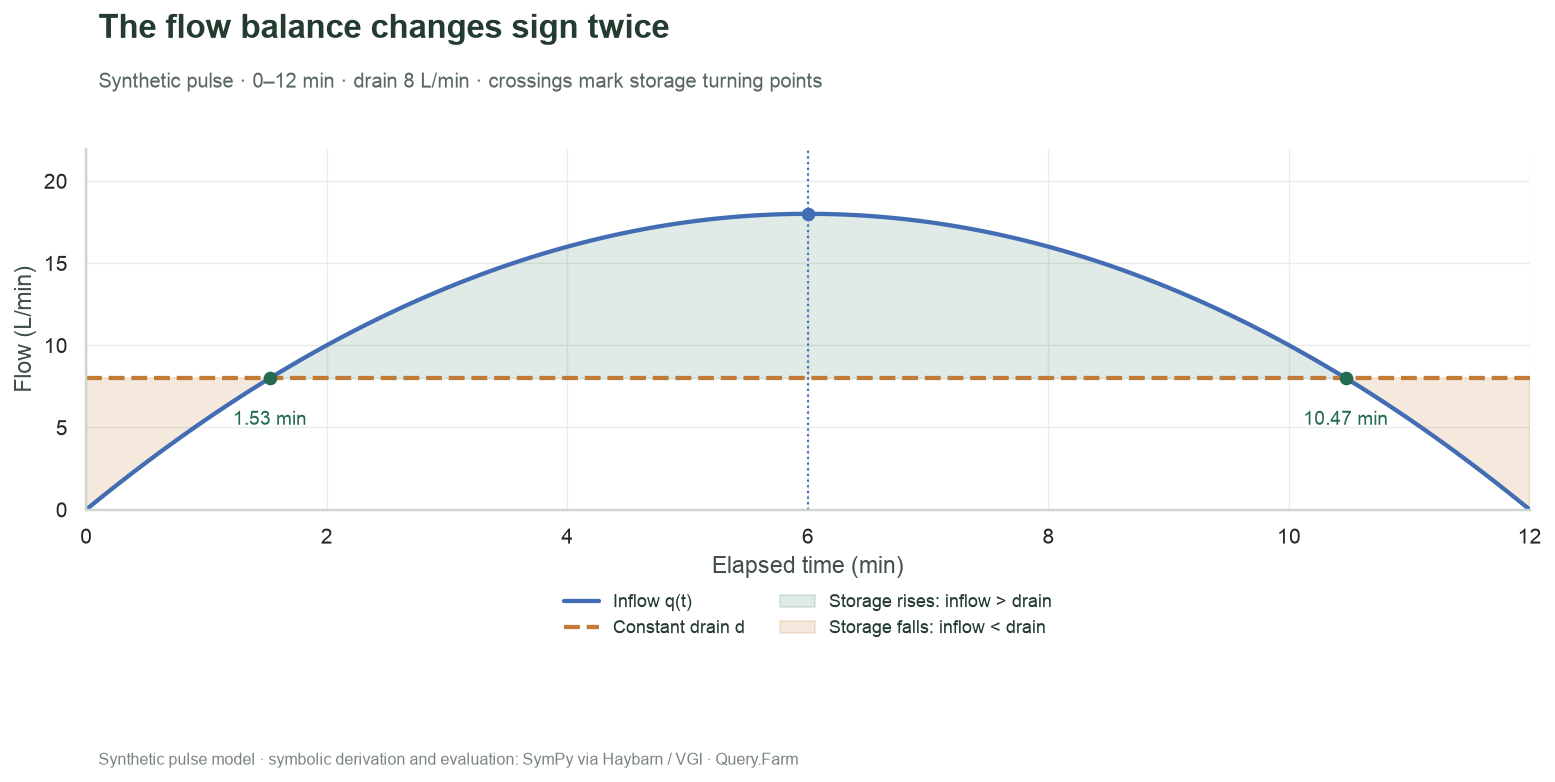

In [18]:
fig, ax = plt.subplots(figsize=(11.4, 5.6))
x = curve.time_min.to_numpy()
q = curve.inflow_l_min.to_numpy()
drain = curve.drain_l_min.to_numpy()
ax.plot(x, q, color=BLUE, label="Inflow q(t)")
ax.plot(x, drain, color=ORANGE, linestyle="--", label="Constant drain d")
ax.fill_between(
    x, q, drain, where=q >= drain, interpolate=True, color=GREEN, alpha=0.14, label="Storage rises: inflow > drain"
)
ax.fill_between(
    x, q, drain, where=q < drain, interpolate=True, color=ORANGE, alpha=0.16, label="Storage falls: inflow < drain"
)
ax.axvline(s.inflow_peak_time_min, color=BLUE, linewidth=1.1, linestyle=":")
ax.scatter([s.inflow_peak_time_min], [s.peak_inflow_l_min], color=BLUE, zorder=4)
for point in turning_points.itertuples():
    if point.interpretation.startswith("local"):
        ax.scatter([point.time_min], [DRAIN_L_MIN], color=GREEN, marker="o", zorder=4)
        ax.annotate(
            f"{point.time_min:.2f} min",
            (point.time_min, DRAIN_L_MIN),
            xytext=(0, -24),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            color=GREEN,
        )
ax.set(xlabel="Elapsed time (min)", ylabel="Flow (L/min)", xlim=(0, DURATION_MIN), ylim=(0, s.peak_inflow_l_min * 1.22))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.19), ncol=2, fontsize=9)
finish_chart(
    fig,
    "The flow balance changes sign twice",
    f"Synthetic pulse · 0–{DURATION_MIN:g} min · drain {DRAIN_L_MIN:g} L/min · crossings mark storage turning points",
)

In [19]:
local_min = turning_points.loc[turning_points.interpretation == "local minimum"].iloc[0]
prose(
    f"The reservoir loses volume until **{local_min.time_min:.2f} min**, then gains while inflow exceeds the drain. "
    f"Inflow has already begun declining after {s.inflow_peak_time_min:.2f} min, "
    "but declining inflow can still be larger than the drain. That positive difference explains why the "
    "interior storage maximum occurs after the inflow peak."
)

The reservoir loses volume until **1.53 min**, then gains while inflow exceeds the drain. Inflow has already begun declining after 6.00 min, but declining inflow can still be larger than the drain. That positive difference explains why the interior storage maximum occurs after the inflow peak.

findfont: Failed to find font weight semibold for Arial, now using 700.


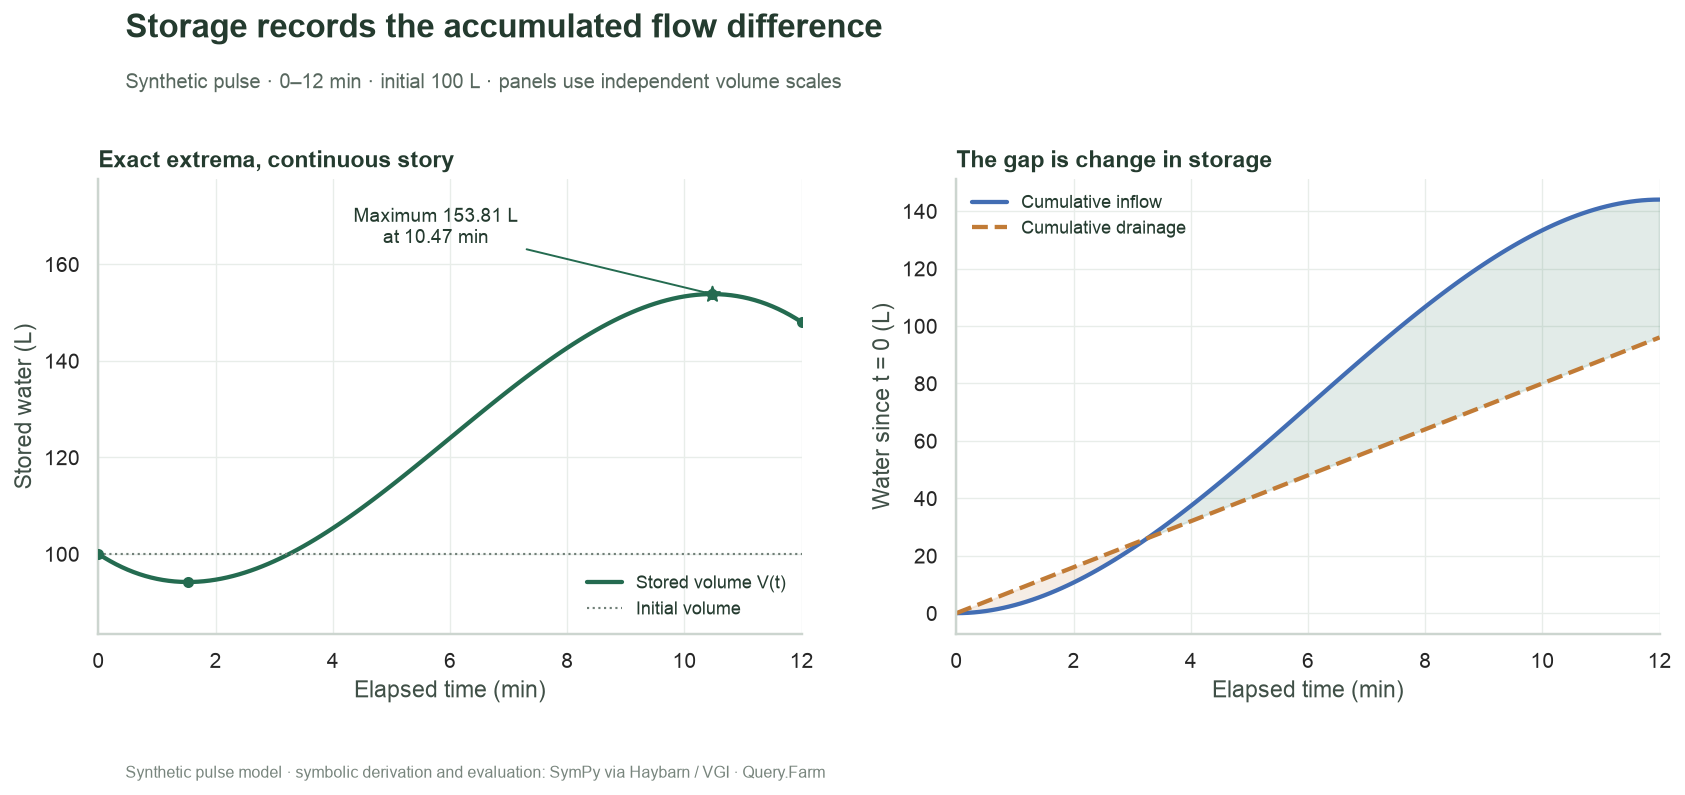

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.7))
ax = axes[0]
ax.plot(curve.time_min, curve.volume_l, color=GREEN, label="Stored volume V(t)")
ax.axhline(INITIAL_VOLUME_L, color="#718078", linewidth=1.1, linestyle=":", label="Initial volume")
ax.scatter(turning_points.time_min, turning_points.volume_l, color=GREEN, s=22, zorder=4)
ax.scatter([s.peak_time_min], [s.peak_volume_l], color=GREEN, s=65, marker="*", zorder=5)
ax.annotate(
    f"Maximum {s.peak_volume_l:.2f} L\nat {s.peak_time_min:.2f} min",
    (s.peak_time_min, s.peak_volume_l),
    xytext=(0.48, 0.94),
    textcoords="axes fraction",
    va="top",
    ha="center",
    fontsize=10,
    arrowprops={"arrowstyle": "-", "color": GREEN},
)
span = max(s.peak_volume_l - s.minimum_volume_l, 1)
ax.set(
    xlabel="Elapsed time (min)",
    ylabel="Stored water (L)",
    title="Exact extrema, continuous story",
    xlim=(0, DURATION_MIN),
    ylim=(max(0, s.minimum_volume_l - span * 0.18), s.peak_volume_l + span * 0.4),
)
ax.legend(loc="lower right", fontsize=9)
ax = axes[1]
ax.plot(curve.time_min, curve.cumulative_inflow_l, color=BLUE, label="Cumulative inflow")
ax.plot(curve.time_min, curve.cumulative_drained_l, color=ORANGE, linestyle="--", label="Cumulative drainage")
ax.fill_between(
    curve.time_min,
    curve.cumulative_inflow_l,
    curve.cumulative_drained_l,
    where=curve.cumulative_inflow_l >= curve.cumulative_drained_l,
    interpolate=True,
    color=GREEN,
    alpha=0.13,
)
ax.fill_between(
    curve.time_min,
    curve.cumulative_inflow_l,
    curve.cumulative_drained_l,
    where=curve.cumulative_inflow_l < curve.cumulative_drained_l,
    interpolate=True,
    color=ORANGE,
    alpha=0.13,
)
ax.set(
    xlabel="Elapsed time (min)",
    ylabel="Water since t = 0 (L)",
    title="The gap is change in storage",
    xlim=(0, DURATION_MIN),
)
ax.legend(loc="upper left", fontsize=9)
finish_chart(
    fig,
    "Storage records the accumulated flow difference",
    f"Synthetic pulse · 0–{DURATION_MIN:g} min · initial {INITIAL_VOLUME_L:g} L · panels use independent volume scales",
)

In [21]:
prose(
    f"**Volume budget at {DURATION_MIN:g} min:** {INITIAL_VOLUME_L:.2f} L initially + "
    f"{s.total_inflow_l:.2f} L entering − {s.total_drained_l:.2f} L drained = **{s.final_volume_l:.2f} L**. "
    f"The end volume is {s.peak_volume_l - s.final_volume_l:.2f} L below the global maximum. "
    "An endpoint-only calculation therefore understates the largest amount of water present during this run. "
    "The curves stop at the pulse boundary; extending this polynomial beyond that domain would invent negative inflow."
)

**Volume budget at 12 min:** 100.00 L initially + 144.00 L entering − 96.00 L drained = **148.00 L**. The end volume is 5.81 L below the global maximum. An endpoint-only calculation therefore understates the largest amount of water present during this run. The curves stop at the pulse boundary; extending this polynomial beyond that domain would invent negative inflow.

## One experiment: increase the drain

With the other defaults unchanged, set **`DRAIN_L_MIN = 12.0`**, then restart and run all. Predict that the interior storage maximum will move **earlier** and **lower**, while the inflow peak stays fixed. The faster drain should reduce final volume by the added drain rate multiplied by the pulse duration.

Compare the **summary table**, the **exact turning-point table**, and the **stored-volume panel**, keeping their units in view. Axes adapt to each run, so use the numbers rather than apparent chart height for the comparison. The README gives a separate-copy command that preserves the successful default notebook.

This is a change in one assumed constant rate, not evidence that a physical drain can deliver it at every water level. The positivity check still applies. Reset **`DRAIN_L_MIN = 8.0`** to recover the default; leave duration, pulse coefficient and initial volume unchanged for this experiment.

In [22]:
prose(
    f"**This run's comparison card:** drain **{DRAIN_L_MIN:g} L/min**; "
    f"inflow peak **{s.inflow_peak_time_min:.3f} min**; "
    f"storage peak **{s.peak_time_min:.3f} min / {s.peak_volume_l:.3f} L**; "
    f"final storage **{s.final_volume_l:.3f} L**. "
    f"Changing from 8 to 12 L/min over the selected {DURATION_MIN:g}-minute interval "
    f"predicts {(12 - 8) * DURATION_MIN:.3f} L less final storage; compare the separate executed copies to test it."
)

**This run's comparison card:** drain **8 L/min**; inflow peak **6.000 min**; storage peak **10.472 min / 153.814 L**; final storage **148.000 L**. Changing from 8 to 12 L/min over the selected 12-minute interval predicts 48.000 L less final storage; compare the separate executed copies to test it.

In [23]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook guide and reproducibility](README.md)